In [4]:
##### Figure 6: distribution of 30x30 exposure by relative deprivation percentile

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import MaxNLocator
from scipy.signal import savgol_filter

In [5]:
##### LOAD DATA

ROOT = Path.cwd().parent
dist_df = pd.read_csv(ROOT / "Results/30x30/exposure_by_deprivation_percentile.csv")

FIG_DIR = ROOT / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
##### STYLING AND HELPERS

COLORS = {
    "Capital": "#2F7C87",
    "Labor": "#C96A3B",
    "Production": "#E5E5E5",
}
PRODUCTION_EDGE = "#C4C4C4"
REFERENCE_COLOR = "#888888"

def smooth(series, window=9, polyorder=2):
    smoothed = savgol_filter(series.values, window_length=window, polyorder=polyorder, mode="interp")
    return pd.Series(smoothed, index=series.index)

def get_series(basis, region, variable, area, estimate="core"):
    sub = dist_df[
        (dist_df["pctl_basis"] == basis) & (dist_df["region"] == region)
        & (dist_df["variable"] == variable) & (dist_df["area"] == area)
        & (dist_df["estimate"] == estimate)
    ].sort_values("percentile")
    return smooth(sub.set_index("percentile")["pct_of_total"])

def draw_exposure_line(ax, basis, region, title, xlabel, ylabel=None, legend=False):
    capital_pct_line = get_series(basis, region, "Capital", "exposed")
    labor_pct_line = get_series(basis, region, "Labor", "exposed")
    production_pct_line = get_series(basis, region, "Production", "exposed")

    ax.fill_between(
        production_pct_line.index, production_pct_line.values,
        color=COLORS["Production"], alpha=0.8, zorder=1, label="Production",
    )
    ax.plot(
        production_pct_line.index, production_pct_line.values,
        color=PRODUCTION_EDGE, linewidth=1.2, zorder=2,
    )
    ax.plot(
        capital_pct_line.index, capital_pct_line.values,
        label="Capital", color=COLORS["Capital"], linewidth=2.2, zorder=4,
    )
    ax.plot(
        labor_pct_line.index, labor_pct_line.values,
        label="Labor", color=COLORS["Labor"], linewidth=2.2, zorder=4,
    )
    ax.axhline(
        1, color=REFERENCE_COLOR, linewidth=1.3, linestyle="--", zorder=4,
        label="Proportional distribution (1%)",
    )

    ax.set_xlabel(xlabel, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12)
    ax.set_ylim(bottom=0)
    ax.set_xlim(1, 100)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis="both", labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(title, fontweight="bold", fontsize=13)
    if legend:
        ax.legend(frameon=False, fontsize=10)

def add_panel_label(ax, letter, x=-0.02, y=1.08, fontsize=16):
    ax.text(
        x, y, letter, transform=ax.transAxes,
        fontsize=fontsize, fontweight="bold", va="bottom", ha="right",
    )

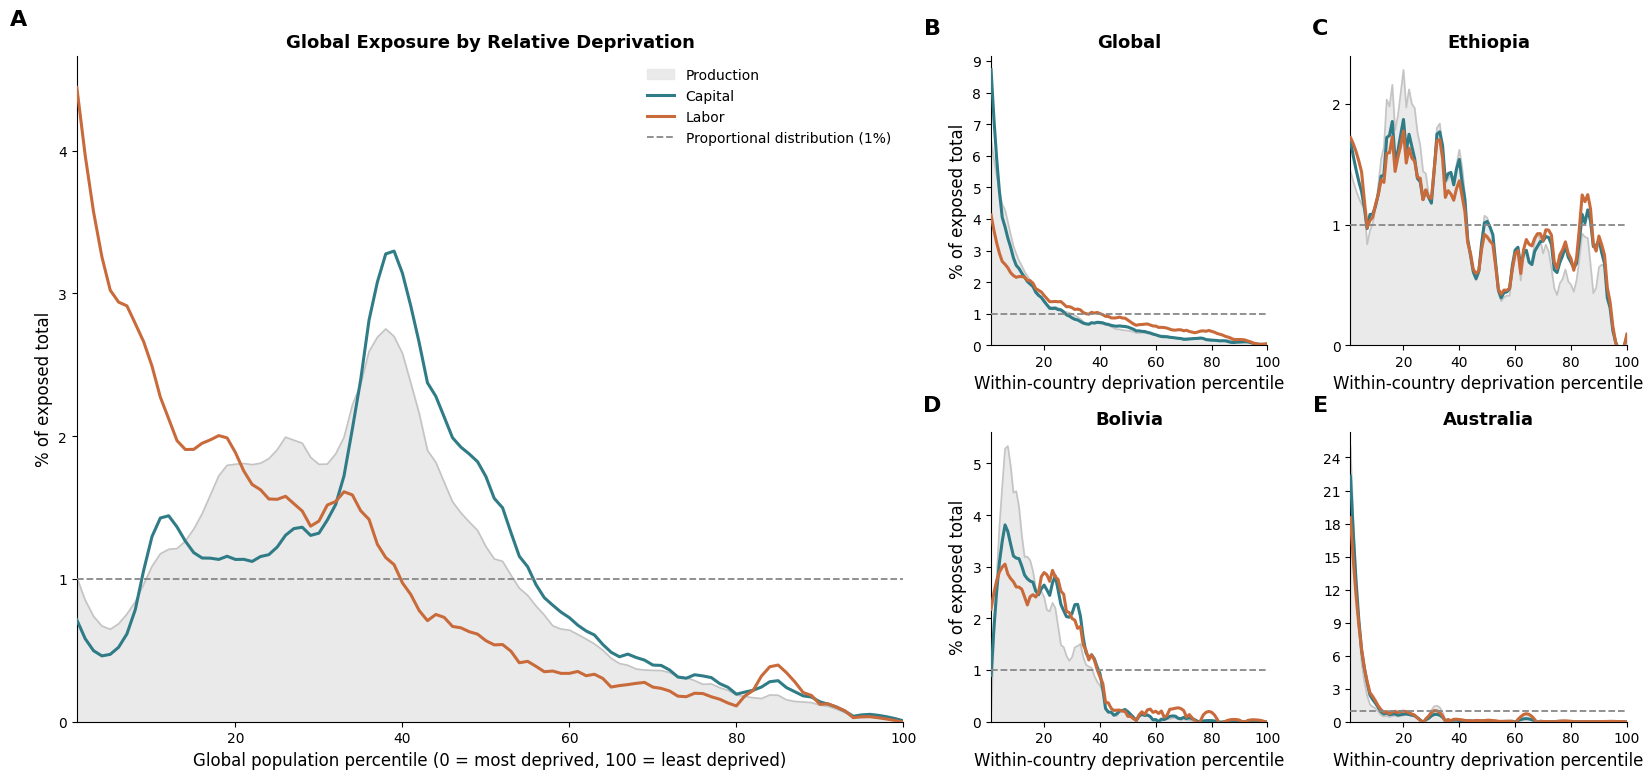

In [7]:
##### FIGURE 6

COUNTRIES = ("ETH", "BOL", "AUS")
COUNTRY_NAMES = {"ETH": "Ethiopia", "BOL": "Bolivia", "AUS": "Australia"}

fig = plt.figure(figsize=(20, 9))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.3, 1], wspace=0.12)

# ---- Left: global exposure by global deprivation percentile ----
ax_left = fig.add_subplot(gs[0])

draw_exposure_line(
    ax_left, "global", "Global",
    title="Global Exposure by Relative Deprivation",
    xlabel="Global population percentile (0 = most deprived, 100 = least deprived)",
    ylabel="% of exposed total",
    legend=True,
)
add_panel_label(ax_left, "A", x=-0.06, y=1.04)

# ---- Right: 2x2 grid, national-percentile exposure ----
gs_right = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[1], wspace=0.3, hspace=0.3)

panel_specs = [("Global", "Global")] + [(COUNTRY_NAMES.get(c, c), c) for c in COUNTRIES]
right_axes = [fig.add_subplot(gs_right[i // 2, i % 2]) for i in range(4)]

nat_xlabel = "Within-country deprivation percentile"
panel_letters = ["B", "C", "D", "E"]

for i, (ax, (panel_title, region)) in enumerate(zip(right_axes, panel_specs)):
    is_left_column = i % 2 == 0
    draw_exposure_line(
        ax, "national", region,
        title=panel_title,
        xlabel=nat_xlabel,
        ylabel="% of exposed total" if is_left_column else None,
        legend=False,
    )
    add_panel_label(ax, panel_letters[i], x=-0.18 if is_left_column else -0.08, y=1.06)

fig.subplots_adjust(top=0.86, bottom=0.12)

plt.savefig(FIG_DIR / "Figure_6_distribution_of_exposure.tiff", dpi=300, bbox_inches="tight")
plt.show()